# Play analysis

Sessions of play from the Overlord's `activity.jsonl` (see `overlord/sessionlog.py`): a session starts
when the game leaves `passive` (any lever pull) and ends when it returns there.

Each session lands in one of three **tiers**:

- **victory**: it reached `victory2`, the real ending (purple freed the spirits).
- **game 1 only**: it won game 1 (the three rounds, on to `party`) but never reached `victory2`.
  Kickouts are here: they won game 1 and then let the final time out.
- **neither**: it ran out of time in one of the three rounds.

**Outcome** is finer: the furthest phase reached, or *kicked out*, or *victory*.

Times are Pacific (America/Los_Angeles). Fetch fresh logs with `tools/overlord_restart.sh --fetch`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# When the piece was open (Pacific): sessions that start in this window. It opened in the small
# hours of Friday night, and Sunday's party day ends 10 am Monday.
OPEN_FROM, OPEN_UNTIL = "2026-11-14 01:00", "2026-11-16 10:00"
LOG_DIR = None          # None: the newest field_logs/<time>/ that has an activity.jsonl

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if LOG_DIR is None:
    LOG_DIR = max(p.parent for p in (root / "field_logs").glob("*/activity.jsonl"))
LOG_DIR = Path(LOG_DIR)
print("reading", LOG_DIR / "activity.jsonl")

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

reading /Users/sam/git_repos/pulleys/field_logs/20261121-203050/activity.jsonl


## Build one row per session

In [2]:
# Phases in game order. diorama_unlocked is from the Nov 14-15 version of the game.
ROUNDS = ["easy_round", "medium_round", "hard_round"]               # game 1
ENDGAME = ["party", "diorama_unlocked", "final_wait", "final"]       # game 1 won
PHASES = ROUNDS + ENDGAME
OUTCOMES = PHASES + ["kicked out", "victory"]

TIERS = ["neither", "game 1 only", "victory"]
TIER_COLOR = {"neither": "#9aa5b1", "game 1 only": "#e5a50a", "victory": "#2e9d5b"}
KICKOUT_COLOR = "#d1495b"

events = []
for line in (LOG_DIR / "activity.jsonl").read_text().splitlines():
    try:
        events.append(json.loads(line))
    except ValueError:
        pass   # a line damaged by a power cut

sessions, cur = [], None
for ev in events:
    e, t = ev["e"], ev["t"]
    if e == "start":
        cur = {"n": ev["n"], "start": t, "pulls": 0, "goal_pulls": 0,
               "states": [ev["state"]], "game1_at": None, "victory_at": None}
    elif cur is None:
        continue
    elif e == "pull":
        cur["pulls"] += 1
        cur["goal_pulls"] += ev.get("g") == "goal"
    elif e == "state":
        s = ev["s"]
        cur["states"].append(s)
        if (s in ENDGAME or s in ("victory2", "kickout")) and cur["game1_at"] is None:
            cur["game1_at"] = t
        if s == "victory2" and cur["victory_at"] is None:
            cur["victory_at"] = t
    elif e == "end":
        cur["end"], cur["why"] = t, ev["why"]
        sessions.append(cur)
        cur = None

def outcome(states):
    if "victory2" in states:
        return "victory"
    if "kickout" in states:
        return "kicked out"
    reached = [PHASES.index(s) for s in states if s in PHASES]
    return PHASES[max(reached)] if reached else "easy_round"

def tier(o):
    if o == "victory":
        return "victory"
    return "neither" if o in ROUNDS else "game 1 only"

df = pd.DataFrame(sessions)
df["outcome"] = pd.Categorical(df["states"].map(outcome), OUTCOMES, ordered=True)
df["tier"] = pd.Categorical(df["outcome"].map(tier).astype(str), TIERS, ordered=True)
df["victory"] = df["tier"] == "victory"
df["game1"] = df["tier"] != "neither"     # won game 1, whatever came after

def local_time(seconds):
    return pd.to_datetime(seconds, unit="s", utc=True).dt.tz_convert("America/Los_Angeles").dt.tz_localize(None)

df["start_dt"], df["end_dt"] = local_time(df["start"]), local_time(df["end"])
# Party days: Saturday runs 10 am Saturday to 10 am Sunday, and so on.
# `hour` counts from the party day's midnight: 1 am the next morning is hour 25.
DAY_STARTS_AT = 10
df["day"] = (df["start_dt"] - pd.Timedelta(hours=DAY_STARTS_AT)).dt.normalize()
df["hours_in"] = (df["start_dt"] - df["day"]).dt.total_seconds() / 3600
df["hour"] = df["hours_in"].astype(int)
df["minutes"] = (df["end"] - df["start"]) / 60
df["minutes_to_game1"] = (df["game1_at"] - df["start"]) / 60
df["minutes_to_victory"] = (df["victory_at"] - df["start"]) / 60

# A session that lasts hours is the game left mid-round, not play. Kept in the counts,
# left out of the duration plots.
STUCK_MINUTES = 60
df["stuck"] = df["minutes"] > STUCK_MINUTES

df = df[(df["start_dt"] >= OPEN_FROM) & (df["start_dt"] < OPEN_UNTIL)].reset_index(drop=True)
DAYS = sorted(df["day"].unique())
DAY_LABEL = {d: pd.Timestamp(d).strftime("%a %b %-d") for d in DAYS}
_open = pd.Timestamp(OPEN_FROM)
if _open > DAYS[0] + pd.Timedelta(hours=DAY_STARTS_AT):   # the first day only had its small hours
    DAY_LABEL[DAYS[0]] += f" (from {_open:%-I %p})".replace("AM", "am").replace("PM", "pm")
def hour_label(h):
    return f"{h % 24:02d}:00"

def tier_handles(extra=()):
    hs = [plt.Rectangle((0, 0), 1, 1, color=TIER_COLOR[t]) for t in TIERS[::-1]]
    return hs + list(extra), TIERS[::-1]

print(f"{len(df)} sessions: {df['game1'].sum()} won game 1 ({df['game1'].mean():.0%}), "
      f"{df['victory'].sum()} reached victory ({df['victory'].mean():.0%})")
print(f"left out of durations (over {STUCK_MINUTES} min, the game left mid-round):")
print(df.loc[df["stuck"], ["n", "start_dt", "end_dt", "minutes", "outcome"]].assign(
    start_dt=lambda d: d["start_dt"].dt.floor("min"), end_dt=lambda d: d["end_dt"].dt.floor("min"),
    minutes=lambda d: d["minutes"].round()).to_string(index=False))
played = df[~df["stuck"]]
df.groupby("day").agg(sessions=("n", "size"), game1=("game1", "sum"), victory=("victory", "sum"),
                      game1_rate=("game1", "mean"), victory_rate=("victory", "mean"),
                      pulls=("pulls", "sum")).join(
    played.groupby("day")["minutes"].median().rename("median_min")).rename(index=DAY_LABEL).round(2)

321 sessions: 137 won game 1 (43%), 100 reached victory (31%)
left out of durations (over 60 min, the game left mid-round):
  n            start_dt              end_dt  minutes          outcome
 77 2026-11-14 03:43:00 2026-11-14 13:39:00    596.0 diorama_unlocked
241 2026-11-15 04:25:00 2026-11-15 17:17:00    773.0       easy_round


,sessions,game1,victory,game1_rate,victory_rate,pulls,median_min
day,,,,,,,
Fri Nov 13 (from 1 am),20,12,3,0.60,0.15,5555,4.78
Sat Nov 14,164,55,36,0.34,0.22,35905,2.77
Sun Nov 15,137,70,61,0.51,0.45,23476,2.72


## Time of day

Each bar is one session, from its start to its end, colored by tier. Each row is a party day,
10 am to 10 am the next morning.

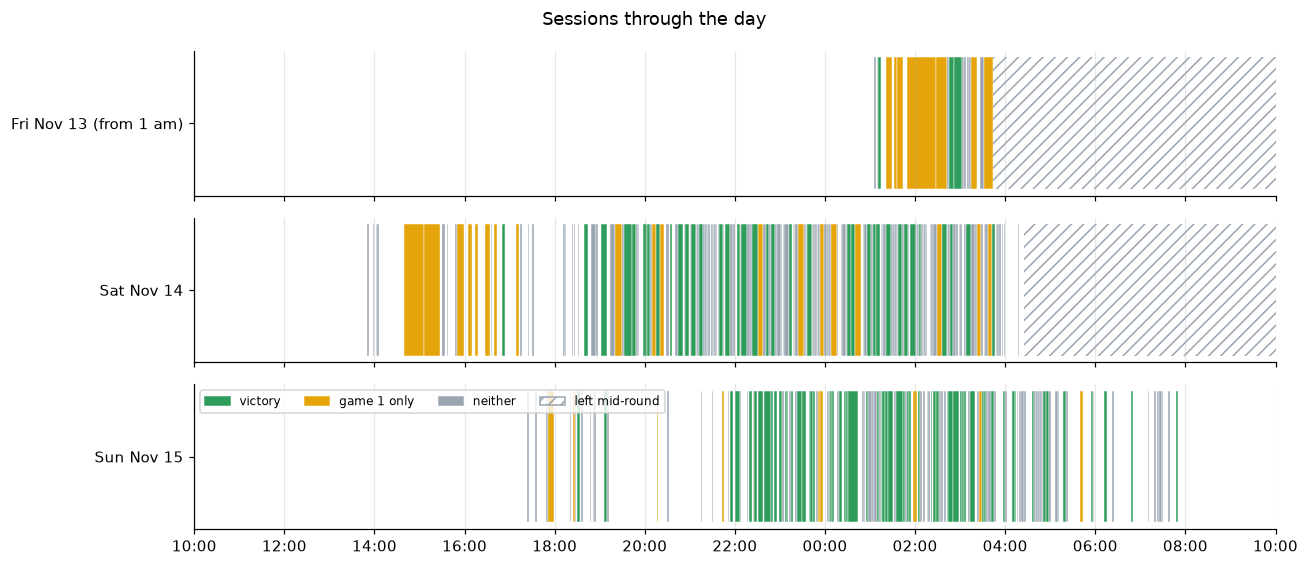

In [3]:
fig, axes = plt.subplots(len(DAYS), 1, figsize=(12, 1.4 * len(DAYS) + 1), sharex=True)
for ax, day in zip(np.atleast_1d(axes), DAYS):
    d = df[df["day"] == day]
    base = pd.Timestamp(day)
    for _, s in d.iterrows():
        x0 = (s["start_dt"] - base).total_seconds() / 3600
        x1 = (s["end_dt"] - base).total_seconds() / 3600
        if s["stuck"]:
            ax.barh(0, x1 - x0, left=x0, height=0.8, color="none", edgecolor="#9aa5b1", hatch="///", lw=0)
        else:
            ax.barh(0, x1 - x0, left=x0, height=0.8, color=TIER_COLOR[s["tier"]], edgecolor="white", lw=0.3)
    ax.set_yticks([0], [DAY_LABEL[day]])
    ax.grid(axis="y", visible=False)
ax.set_xlim(DAY_STARTS_AT, DAY_STARTS_AT + 24)
ticks = range(DAY_STARTS_AT, DAY_STARTS_AT + 25, 2)
ax.set_xticks(ticks, [hour_label(h) for h in ticks])
handles, labels = tier_handles([plt.Rectangle((0, 0), 1, 1, fc="none", ec="#9aa5b1", hatch="///")])
ax.legend(handles, labels + ["left mid-round"], loc="upper left", ncols=4, fontsize=8)
fig.suptitle("Sessions through the day")
fig.tight_layout()

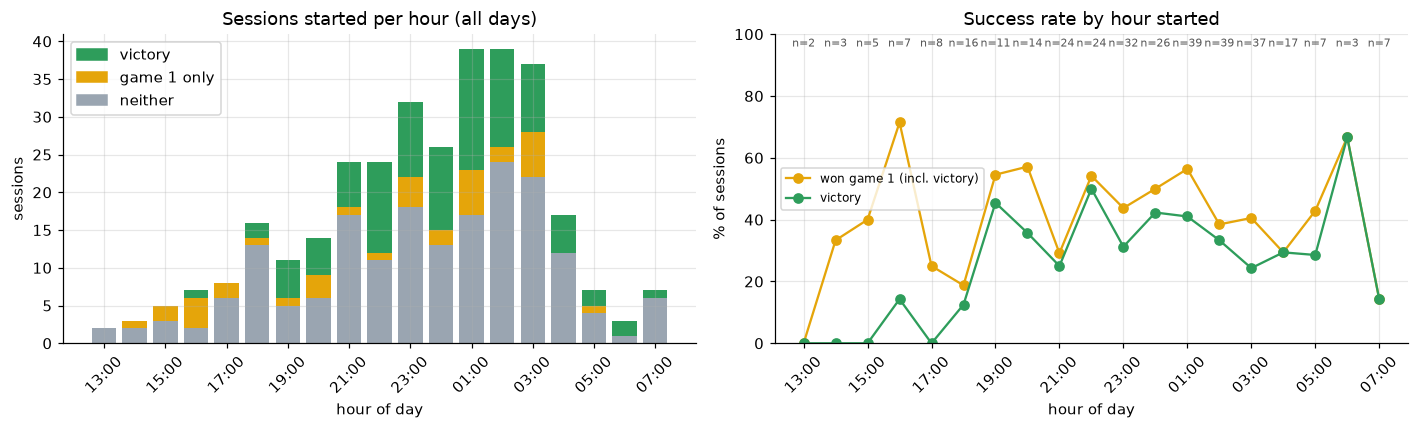

In [4]:
hours = range(df["hour"].min(), df["hour"].max() + 1)
by_hour = pd.crosstab(df["hour"], df["tier"]).reindex(index=hours, columns=TIERS, fill_value=0)
total = by_hour.sum(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
bottom = np.zeros(len(by_hour))
for t in TIERS:
    ax1.bar(by_hour.index, by_hour[t], bottom=bottom, color=TIER_COLOR[t], label=t)
    bottom += by_hour[t].values
ax1.set(title="Sessions started per hour (all days)", xlabel="hour of day", ylabel="sessions")
handles, labels = tier_handles()
ax1.legend(handles, labels)

n = total.replace(0, np.nan)
ax2.plot(by_hour.index, (by_hour["game 1 only"] + by_hour["victory"]) / n * 100, "o-",
         color=TIER_COLOR["game 1 only"], label="won game 1 (incl. victory)")
ax2.plot(by_hour.index, by_hour["victory"] / n * 100, "o-", color=TIER_COLOR["victory"], label="victory")
for h, k in total.items():
    if k:
        ax2.annotate(f"n={k}", (h, 96), ha="center", fontsize=7, color="#555")
ax2.set(title="Success rate by hour started", xlabel="hour of day", ylabel="% of sessions", ylim=(0, 100))
ax2.legend(loc="center left", fontsize=8)
for ax in (ax1, ax2):
    ax.set_xticks(list(hours)[::2], [hour_label(h) for h in list(hours)[::2]], rotation=45)
fig.tight_layout()

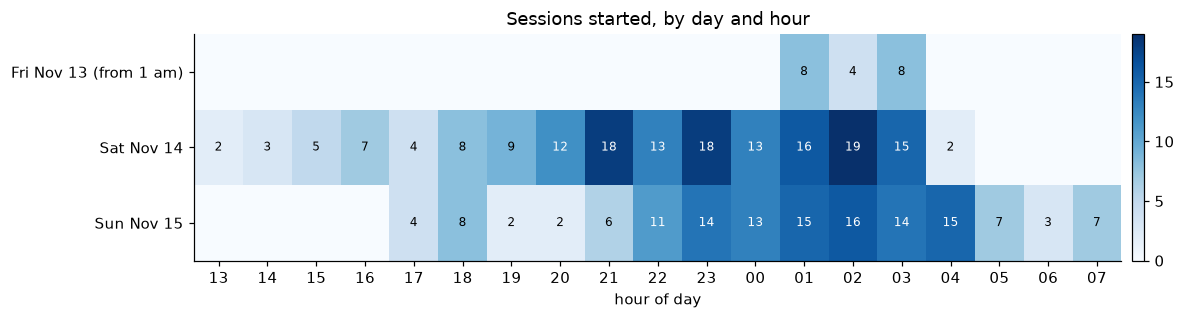

In [5]:
grid = df.pivot_table(index="day", columns="hour", values="n", aggfunc="size", fill_value=0) \
    .reindex(columns=hours, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 0.6 * len(DAYS) + 1.2))
im = ax.imshow(grid, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(grid.columns)), [hour_label(h)[:2] for h in grid.columns])
ax.set_yticks(range(len(grid.index)), [DAY_LABEL[d] for d in grid.index])
for (i, j), v in np.ndenumerate(grid.values):
    if v:
        ax.text(j, i, v, ha="center", va="center", fontsize=8,
                color="white" if v > grid.values.max() / 2 else "black")
ax.grid(False)
ax.set(title="Sessions started, by day and hour", xlabel="hour of day")
fig.colorbar(im, ax=ax, pad=0.01)
fig.tight_layout()

## Play duration

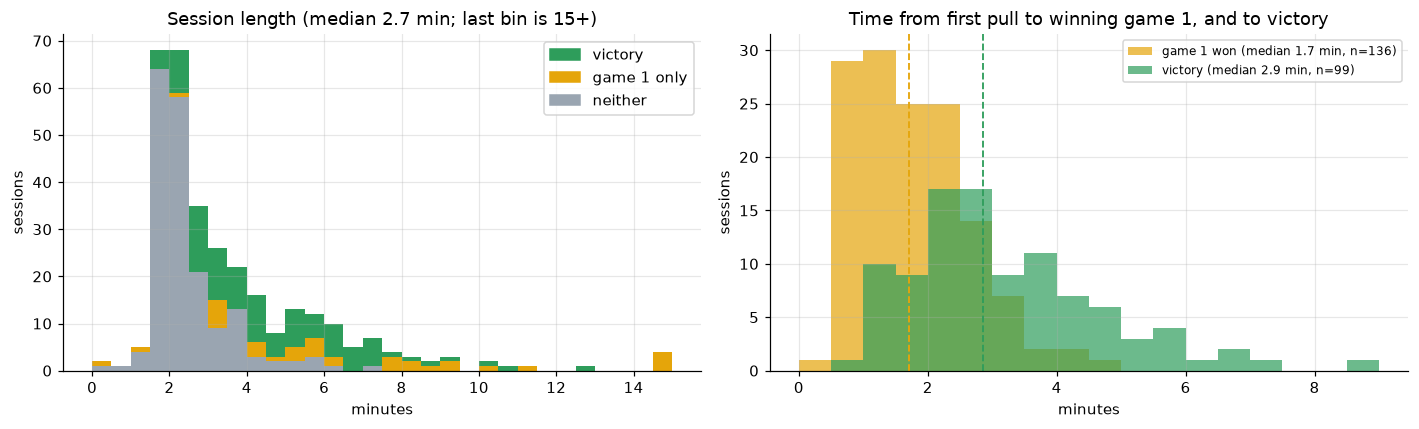

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
CAP = 15   # minutes; longer sessions go in the last bin
bins = np.arange(0, CAP + 0.5, 0.5)
clipped = played["minutes"].clip(upper=CAP - 0.01)
ax1.hist([clipped[played["tier"] == t] for t in TIERS], bins=bins, stacked=True,
         color=[TIER_COLOR[t] for t in TIERS], label=TIERS)
ax1.set(title=f"Session length (median {played['minutes'].median():.1f} min; last bin is {CAP}+)",
        xlabel="minutes", ylabel="sessions")
handles, labels = tier_handles()
ax1.legend(handles, labels)

g1, v = df["minutes_to_game1"].dropna(), df["minutes_to_victory"].dropna()
bins = np.arange(0, max(g1.max(), v.max()) + 0.5, 0.5)
ax2.hist(g1, bins=bins, color=TIER_COLOR["game 1 only"], alpha=0.7,
         label=f"game 1 won (median {g1.median():.1f} min, n={len(g1)})")
ax2.hist(v, bins=bins, color=TIER_COLOR["victory"], alpha=0.7,
         label=f"victory (median {v.median():.1f} min, n={len(v)})")
for x, t in [(g1.median(), "game 1 only"), (v.median(), "victory")]:
    ax2.axvline(x, color=TIER_COLOR[t], ls="--", lw=1.2)
ax2.set(title="Time from first pull to winning game 1, and to victory", xlabel="minutes", ylabel="sessions")
ax2.legend(fontsize=8)
fig.tight_layout()

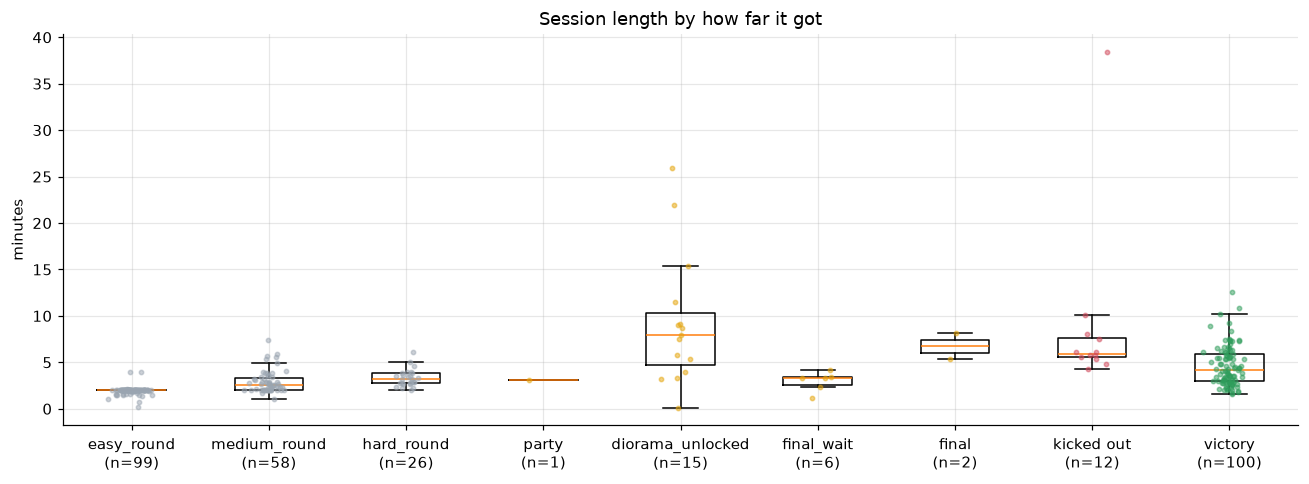

In [7]:
OUTCOME_COLOR = {o: TIER_COLOR[tier(o)] for o in OUTCOMES} | {"kicked out": KICKOUT_COLOR}

fig, ax = plt.subplots(figsize=(12, 4.5))
order = [o for o in OUTCOMES if (played["outcome"] == o).any()]
data = [played.loc[played["outcome"] == o, "minutes"] for o in order]
ax.boxplot(data, tick_labels=[f"{o}\n(n={len(d)})" for o, d in zip(order, data)], showfliers=False)
for i, d in enumerate(data, 1):
    ax.scatter(np.random.normal(i, 0.06, len(d)), d, s=8, alpha=0.5, color=OUTCOME_COLOR[order[i - 1]], zorder=3)
ax.set(title="Session length by how far it got", ylabel="minutes")
fig.tight_layout()

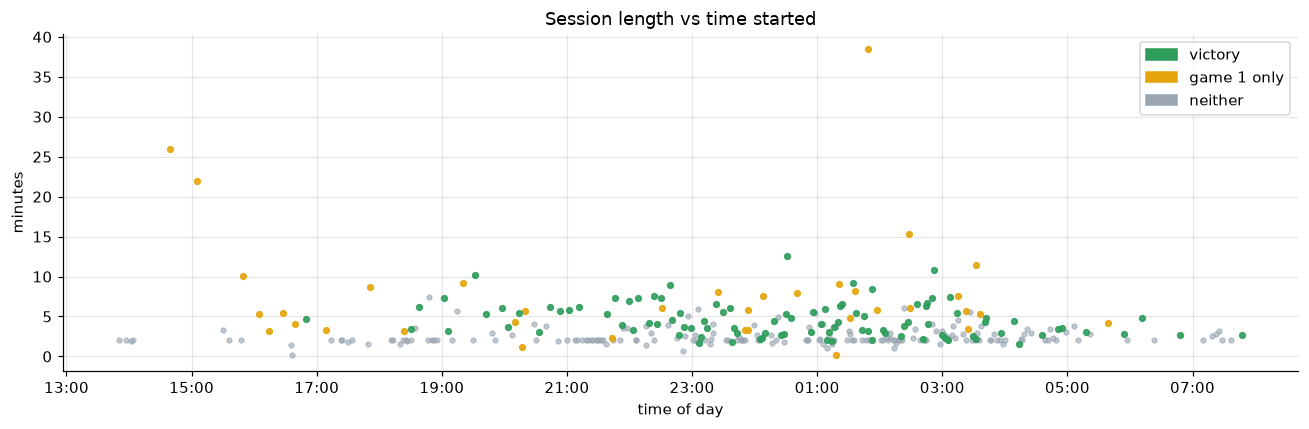

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
tod = played["hours_in"]
for t, size, alpha in [("neither", 10, 0.6), ("game 1 only", 14, 0.9), ("victory", 14, 0.9)]:
    m = played["tier"] == t
    ax.scatter(tod[m], played.loc[m, "minutes"], s=size, alpha=alpha, color=TIER_COLOR[t], label=t, zorder=3)
ticks = range(int(tod.min()), int(tod.max()) + 2, 2)
ax.set_xticks(ticks, [hour_label(h) for h in ticks])
ax.set(title="Session length vs time started", xlabel="time of day", ylabel="minutes")
handles, labels = tier_handles()
ax.legend(handles, labels)
fig.tight_layout()

## Success

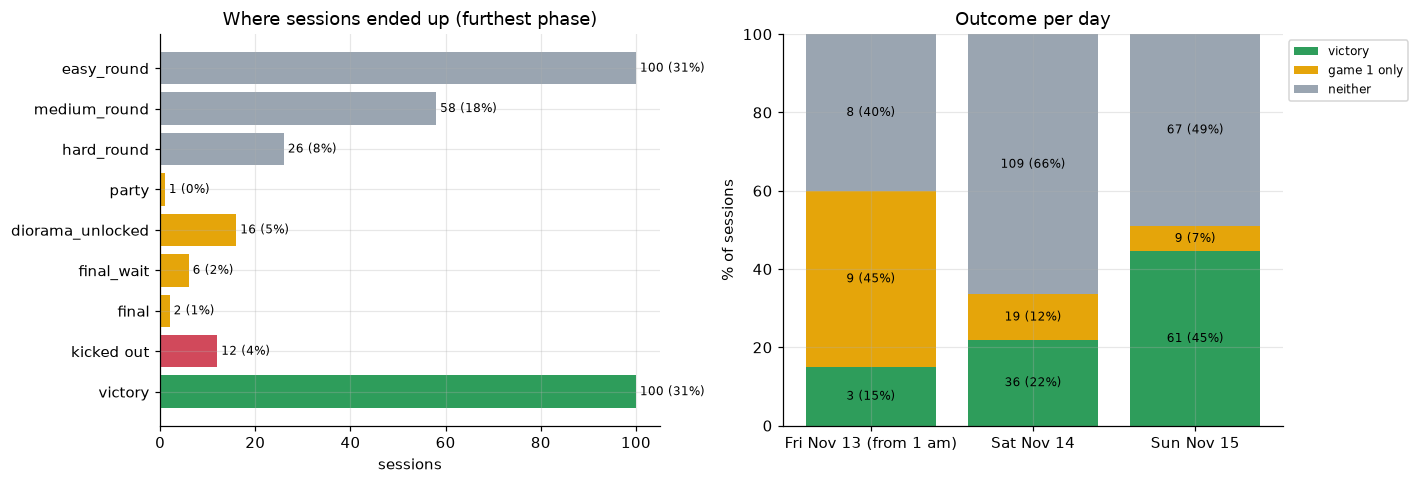

In [9]:
counts = df["outcome"].value_counts().reindex(order).fillna(0).astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.barh(range(len(counts)), counts, color=[OUTCOME_COLOR[o] for o in counts.index])
ax1.set_yticks(range(len(counts)), counts.index)
ax1.invert_yaxis()
for i, k in enumerate(counts):
    ax1.text(k, i, f" {k} ({k / len(df):.0%})", va="center", fontsize=8)
ax1.set(title="Where sessions ended up (furthest phase)", xlabel="sessions")

daily = pd.crosstab(df["day"], df["tier"]).reindex(columns=TIERS, fill_value=0)
share = daily.div(daily.sum(axis=1), axis=0) * 100
x = np.arange(len(daily))
bottom = np.zeros(len(daily))
for t in TIERS[::-1]:      # victory at the bottom, so its share reads off the axis
    ax2.bar(x, share[t], bottom=bottom, color=TIER_COLOR[t], label=t)
    for i, (pct, k) in enumerate(zip(share[t], daily[t])):
        if pct >= 6:
            ax2.text(i, bottom[i] + pct / 2, f"{k} ({pct:.0f}%)", ha="center", va="center", fontsize=8)
    bottom += share[t].values
ax2.set_xticks(x, [DAY_LABEL[d] for d in daily.index])
ax2.set(title="Outcome per day", ylabel="% of sessions", ylim=(0, 100))
ax2.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()

In [10]:
# Many sessions are one stray pull that times out in easy_round. Leaving those out:
MIN_PULLS = 5
serious = df[df["pulls"] >= MIN_PULLS]
print(f"sessions with at least {MIN_PULLS} pulls: {len(serious)} of {len(df)}; "
      f"won game 1 {serious['game1'].sum()} ({serious['game1'].mean():.0%}), "
      f"victory {serious['victory'].sum()} ({serious['victory'].mean():.0%})")
d = serious.groupby("day").agg(sessions=("n", "size"), game1=("game1", "sum"), victory=("victory", "sum"))
d.assign(game1_rate=(d["game1"] / d["sessions"]).round(2),
         victory_rate=(d["victory"] / d["sessions"]).round(2),
         # of those who won game 1, how many went on to victory
         victory_given_game1=(d["victory"] / d["game1"]).round(2)).rename(index=DAY_LABEL)

sessions with at least 5 pulls: 283 of 321; won game 1 130 (46%), victory 100 (35%)


,sessions,game1,victory,game1_rate,victory_rate,victory_given_game1
day,,,,,,
Fri Nov 13 (from 1 am),17,10,3,0.59,0.18,0.30
Sat Nov 14,148,52,36,0.35,0.24,0.69
Sun Nov 15,118,68,61,0.58,0.52,0.90
